# Generalisation check: Brain Observatory (independent Neuropixels session type)

Does correlation-edge p-SFA's within-subject reconstruction of pupil-linked arousal
(`Figure_3_Neuropixels.ipynb`, Panel B -- cells 4-5) generalise to a second, independent
Allen Institute Neuropixels session type? "Brain Observatory 1.1" sessions use a
different stimulus/experimental paradigm and animal cohort from the main text's
"functional_connectivity" sessions, and are native ~5-minute recordings -- about 6x
shorter than functional_connectivity's ~30-minute sessions.

This notebook reruns the exact Panel B within-subject pipeline unchanged (same
`EDGE_WIN=1501` ~= 12 s window as the main text, same `N_COMPONENTS=3`, same
`component0_scores` estimator, same correlation-edges vs. node-variance comparison),
pointed at the Brain Observatory data instead of functional_connectivity. Area
coverage is uneven enough across Brain Observatory subjects that pooled/LOSO transfer
is not attempted here; this is a within-subject-only replication, using the same
`area_filter=None` (flexible per-subject area set) as Panel B.

## Configuration

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))

from src.neuropixels_data import list_subjects, load_subject_lfp
from src.features import build_feature
from src.util import moving_average_centered
from src.sweeps import component0_scores
from src.sfa import affine_align, r2_score, pearson_r

import os

os.environ["BRAIN_OBSERVATORY_DATA_ROOT"] = "/Users/ritviksharma/Projects/code_pSFA/experiments/neuropixels/brain_observatory"
_data_root_env = os.environ.get("BRAIN_OBSERVATORY_DATA_ROOT")
assert _data_root_env, "Set the BRAIN_OBSERVATORY_DATA_ROOT environment variable to your local Brain Observatory data copy."
DATA_ROOT = Path(_data_root_env)
assert DATA_ROOT.exists(), f"Brain Observatory data not found at {DATA_ROOT} -- check BRAIN_OBSERVATORY_DATA_ROOT."

MEDIA_DIR = Path("outputs/figures/neuropixels")
CACHE_DIR = Path("outputs/results/neuropixels")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

DOWNSAMPLE_FACTOR = 10     # 1250 Hz -> 125 Hz, same native rate as functional_connectivity
EDGE_WIN          = 1501   # ~12 s -- matches main-text Panel B exactly
N_COMPONENTS      = 3      # matches Figure_3_Neuropixels.ipynb Panel B

# No known-bad-subject list exists for Brain Observatory (unlike functional_connectivity's
# CORRUPTED_SIDS). A direct check over all 21 usable subjects at EDGE_WIN=1501 found none
# needed: every subject has >=4 VIS-area columns, per-node variance is non-degenerate and
# consistent in order of magnitude, and no subject produced a non-finite R^2.
BRAIN_OBSERVATORY_CORRUPTED_SIDS = []

def drop_corrupted(df):
    return df[~df.index.astype(str).isin(BRAIN_OBSERVATORY_CORRUPTED_SIDS)]

def zscore(x):
    return (x - np.nanmean(x)) / np.nanstd(x)

ACCENT="#2a6f72"; ACCENT_D="#1d4f51"; GOLD="#c58a3d"; GOLD_D="#8f5f24"
MUTED="#8a8f99"; INK="#1f2328"; INK_SOFT="#4a4f57"; RULE="#e3e0d8"

subjects = list_subjects(DATA_ROOT)
print(f"EDGE_WIN = {EDGE_WIN} samples =~ {EDGE_WIN / (1250/DOWNSAMPLE_FACTOR):.0f} s "
      f"at {1250//DOWNSAMPLE_FACTOR} Hz")
print(f"Found {len(subjects)} candidate subject(s).")

EDGE_WIN = 1501 samples =~ 12 s at 125 Hz
Found 21 candidate subject(s).


## Within-subject reconstruction

Direct adaptation of `Figure_3_Neuropixels.ipynb` cell 4 (the Panel B loop), pointed at
`BRAIN_OBSERVATORY_DATA_ROOT` instead of `NEUROPIXELS_DATA_ROOT`. No other changes to the
estimator or windowing.

In [2]:
within_rows = []
SUBJECT_DATA_CACHE = {}   # sid -> (X_s, d_s_raw, t_s), reused by the plotting cell below
for sid in subjects:
    print(sid)
    try:
        out = load_subject_lfp(DATA_ROOT / sid, DOWNSAMPLE_FACTOR, area_filter=None)
        if out is None:
            continue
        X_s, d_s, t_s, areas_s = out
        SUBJECT_DATA_CACHE[sid] = (X_s, d_s, t_s)
        d_sm = moving_average_centered(d_s[:, None], EDGE_WIN)[:, 0]

        Rho   = build_feature("edges-corr", X_s, EDGE_WIN)
        X_var = build_feature("node-var", X_s, EDGE_WIN)

        T = min(len(d_sm), Rho.shape[0], X_var.shape[0])
        d_, Rho_, X_var_ = d_sm[:T], Rho[:T], X_var[:T]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r2_corr, _ = component0_scores(Rho_,   d_, n_components=N_COMPONENTS)
            r2_var, _  = component0_scores(X_var_, d_, n_components=N_COMPONENTS)

        within_rows.append(dict(subject=sid, R2_corr=r2_corr, R2_nodevar=r2_var, T_eff=T))
    except Exception as exc:
        print(f"  {sid}: [skip] {exc}")

within_df = pd.DataFrame(within_rows).set_index("subject")
within_df.to_csv(CACHE_DIR / "within_subject_brain_observatory.csv")
print(f"n = {len(within_df)} subjects")
display(within_df.round(3))

743475441
744228101
750749662
751348571
754312389
754829445
755434585
756029989
757216464
757970808
758798717
759883607
760345702
761418226
762602078
763673393
773418906
791319847
797828357
798911424
799864342
n = 21 subjects


,R2_corr,R2_nodevar,T_eff
subject,,,
743475441,0.341,0.234,36156
744228101,0.354,0.017,36156
750749662,0.507,0.467,36156
751348571,0.016,0.003,36156
754312389,0.896,0.849,36156
754829445,0.825,0.783,36156
755434585,0.484,0.367,36156
756029989,0.773,0.865,36158
757216464,0.784,0.583,36156


## Cohort summary and example subject

Same combined two-panel figure as `Figure_3_Neuropixels.ipynb` cell 5: left panel is the
paired correlation-edges vs. node-variance boxplot across all subjects, right panel is one
subject's SFA component-0 trace overlaid on pupil area, with R² annotated. The highlighted
subject is auto-picked by highest `R2_corr`.

findfont: Failed to find font weight semibold, now using 700.


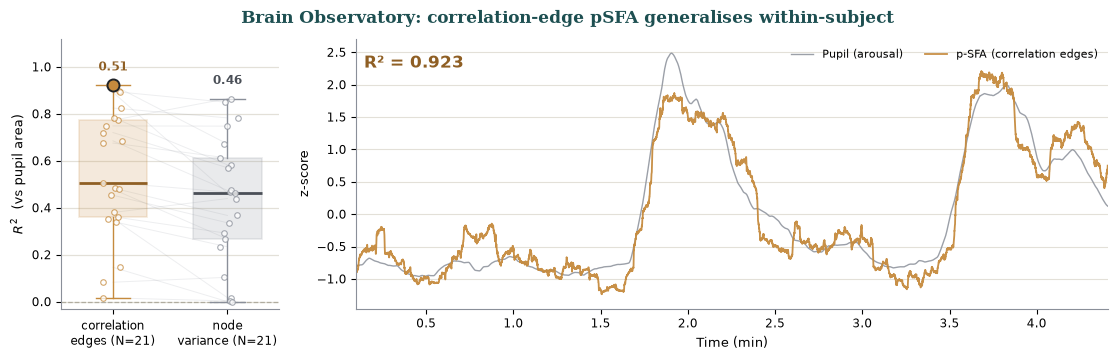

Plotted subject: 797828357  (R2 = 0.923)   [best subject overall: 797828357]
median R2: correlation edges = 0.507   node variance = 0.463


In [3]:
SELECTED_SID = None  # set to a subject id string to plot that subject; None = auto-pick best

gdf         = drop_corrupted(within_df)
corr_vals   = gdf["R2_corr"].dropna().values
nv_vals     = gdf["R2_nodevar"].dropna().values

BEST_SID = drop_corrupted(within_df)["R2_corr"].idxmax()
PLOT_SID = SELECTED_SID if SELECTED_SID is not None else BEST_SID
if PLOT_SID not in SUBJECT_DATA_CACHE:
    raise ValueError(f"{PLOT_SID!r} not in SUBJECT_DATA_CACHE -- available: {sorted(SUBJECT_DATA_CACHE)}")

X_b, d_b, t_b = SUBJECT_DATA_CACHE[PLOT_SID]
d_sm_b = moving_average_centered(d_b[:, None], EDGE_WIN)[:, 0]
Rho_b = build_feature("edges-corr", X_b, EDGE_WIN)
n_b = min(len(d_sm_b), Rho_b.shape[0])
Rho_b, d_sm_b = Rho_b[:n_b], d_sm_b[:n_b]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    r2_b, absr_b, y_b_raw = component0_scores(Rho_b, d_sm_b, n_components=N_COMPONENTS,
                                              return_component=True)
    y_b, _, _ = affine_align(y_b_raw, d_sm_b)  # sign-fix + scale for the overlay plot below
half = (EDGE_WIN - 1) // 2
t_sm = (t_b[half: half + len(d_sm_b)] - t_b[0]) / 60.0

fig = plt.figure(figsize=(13.5, 3.6))
gs  = fig.add_gridspec(1, 2, width_ratios=[0.55, 1.9], wspace=0.16, top=0.86)
axL = fig.add_subplot(gs[0]); axR = fig.add_subplot(gs[1])

axL.set_axisbelow(True); axL.yaxis.grid(True, color=RULE, lw=0.9)
groups = [(corr_vals, GOLD, GOLD_D), (nv_vals, MUTED, INK_SOFT)]
rng = np.random.default_rng(0)
for pos, (vals, col, cold) in enumerate(groups, 1):
    bp = axL.boxplot(vals, positions=[pos], widths=0.6, patch_artist=True,
                      showfliers=False, whis=(0, 100),
                      medianprops=dict(color=cold, lw=2.0), boxprops=dict(edgecolor=col, lw=1.2),
                      whiskerprops=dict(color=col, lw=1.0), capprops=dict(color=col, lw=1.0))
    bp["boxes"][0].set_facecolor(col); bp["boxes"][0].set_alpha(0.18)
    axL.scatter(np.full(len(vals), pos) + rng.uniform(-0.09, 0.09, len(vals)), vals, s=16,
                color="white", edgecolors=col, linewidths=0.8, zorder=3, alpha=0.75)
    axL.text(pos, vals.max() + 0.05, f"{np.median(vals):.2f}", va="bottom", ha="center",
             fontsize=8.5, color=cold, fontweight="bold")
# faded lines connecting each subject's pair of values across the two categories
for sid in gdf.index:
    v_corr, v_nv = gdf.loc[sid, "R2_corr"], gdf.loc[sid, "R2_nodevar"]
    if np.isfinite(v_corr) and np.isfinite(v_nv):
        axL.plot([1, 2], [v_corr, v_nv], color=MUTED, alpha=0.15, lw=0.7, zorder=1)
# highlight the plotted subject's correlation-edges point only (not node variance)
if PLOT_SID in gdf.index:
    v_corr = gdf.loc[PLOT_SID, "R2_corr"]
    axL.scatter([1], [v_corr], s=75, facecolor=GOLD, edgecolors=INK, linewidths=1.4, zorder=4)
axL.axhline(0, color="#b0ac9f", lw=0.9, ls="--", zorder=1)
axL.set_xticks([1, 2])
axL.set_xticklabels([f"correlation\nedges (N={len(corr_vals)})", f"node\nvariance (N={len(nv_vals)})"], fontsize=8.5)
axL.set_xlim(0.55, 2.45); axL.set_ylim(-0.03, 1.12)
axL.set_ylabel(r"$R^2$  (vs pupil area)", fontsize=9.5)
axL.tick_params(labelsize=8.5)
axL.spines[["top", "right"]].set_visible(False); axL.spines[["left", "bottom"]].set_color(MUTED)

axR.set_axisbelow(True); axR.yaxis.grid(True, color=RULE, lw=0.8)
axR.plot(t_sm, zscore(d_sm_b), color=MUTED, lw=1.0, alpha=0.85, label="Pupil (arousal)")
axR.plot(t_sm, zscore(y_b),    color=GOLD,  lw=1.3, alpha=0.95, label="p-SFA (correlation edges)")
axR.text(0.01, 0.94, f"R\u00b2 = {r2_b:.3f}",
         transform=axR.transAxes, ha="left", va="top", fontsize=12, color=GOLD_D, fontweight="bold")
axR.set_xlim(t_sm.min(), t_sm.max()); axR.margins(y=0.06)
axR.set_xlabel("Time (min)", fontsize=9.5); axR.set_ylabel("z-score", fontsize=9.5)
axR.tick_params(labelsize=8.5)
axR.legend(loc="upper right", frameon=False, fontsize=8, ncol=2)
axR.spines[["top", "right"]].set_visible(False); axR.spines[["left", "bottom"]].set_color(MUTED)

fig.suptitle("Brain Observatory: correlation-edge pSFA generalises within-subject",
             fontfamily="serif", color=ACCENT_D, fontsize=12, fontweight="semibold", y=0.94)
fname = "fig_appendix_brain_observatory_cohort" if PLOT_SID == BEST_SID else f"fig_appendix_brain_observatory_cohort_{PLOT_SID}"
fig.savefig(MEDIA_DIR / f"{fname}.svg", transparent=True, bbox_inches="tight")
fig.savefig(MEDIA_DIR / f"{fname}.png", dpi=300, transparent=True, bbox_inches="tight")
plt.show()

print(f"Plotted subject: {PLOT_SID}  (R2 = {r2_b:.3f})   [best subject overall: {BEST_SID}]")
print(f"median R2: correlation edges = {np.median(corr_vals):.3f}   node variance = {np.median(nv_vals):.3f}")